In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/dataset.csv')

In [ ]:
# Display the first 5 rows of the DataFrame
display(df.head())

,State,Crop,CostCultivation,CostCultivation2,Production,Yield,Temperature,RainFall Annual,Price
0,Uttar Pradesh,ARHAR,9794.05,9800.25,1941.55,9.83,28.96,3373.2,19589.10
1,Karnataka,ARHAR,10593.15,10594.15,2172.46,7.47,29.22,3520.7,21187.30
2,Gujarat,ARHAR,13468.82,13469.82,1898.30,9.59,28.47,2957.4,26938.64
3,Andhra Pradesh,ARHAR,17051.66,17052.66,3670.54,6.42,28.49,3079.6,34104.32
4,Maharashtra,ARHAR,17130.55,17131.55,2775.80,8.72,28.30,2566.7,34262.10


Now that we have loaded the data, let's explore some plotting techniques. I will start with a histogram to show the distribution of a numerical column, and then a scatter plot to visualize the relationship between two numerical columns.

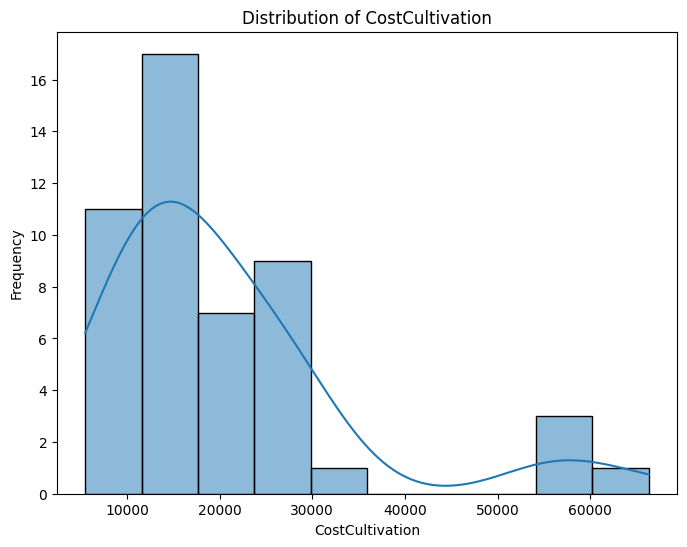

In [ ]:
# Identify numerical columns for plotting
numerical_cols = df.select_dtypes(include=['number']).columns

if len(numerical_cols) >= 1:
    # Plot a histogram of the first numerical column
    plt.figure(figsize=(8, 6))
    sns.histplot(df[numerical_cols[0]], kde=True)
    plt.title(f'Distribution of {numerical_cols[0]}')
    plt.xlabel(numerical_cols[0])
    plt.ylabel('Frequency')
    plt.show()
else:
    print("No numerical columns found to plot histograms.")

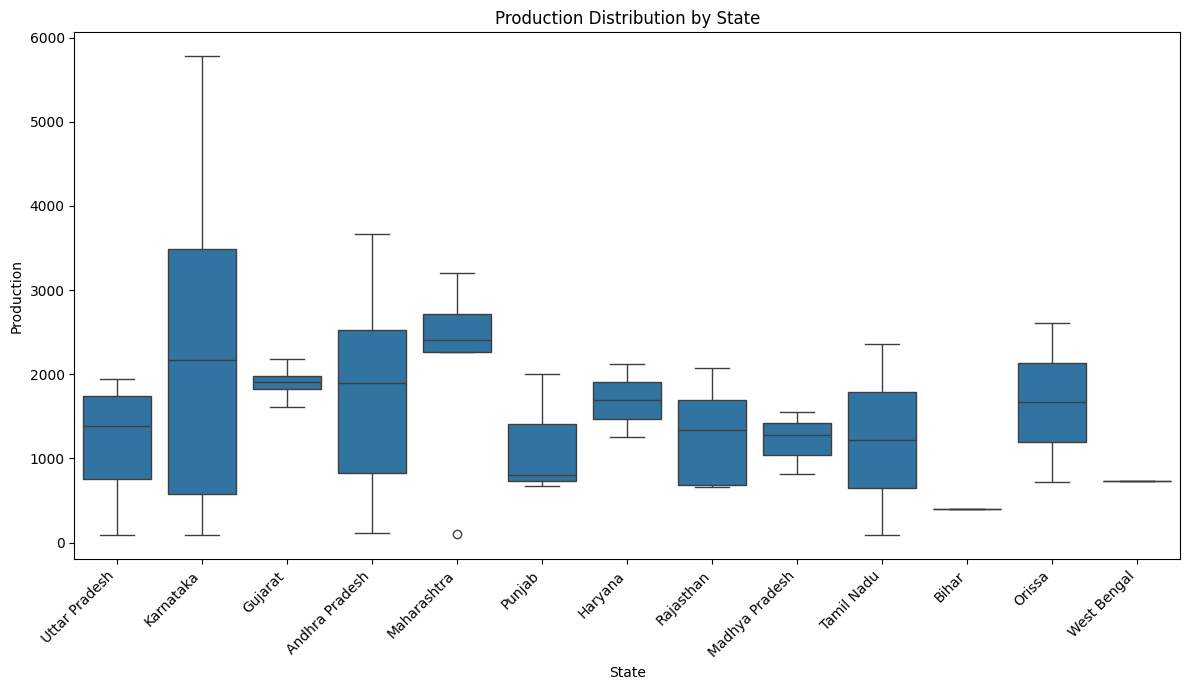

In [ ]:
# Box plot: Distribution of 'Production' across 'State'
if 'State' in df.columns and 'Production' in df.columns:
    plt.figure(figsize=(12, 7))
    sns.boxplot(x='State', y='Production', data=df)
    plt.title('Production Distribution by State')
    plt.xlabel('State')
    plt.ylabel('Production')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("Cannot create box plot: 'State' or 'Production' column not found.")

/tmp/ipykernel_2031/2631475317.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Crop', y='CostCultivation', data=avg_cost_by_crop, palette='viridis')


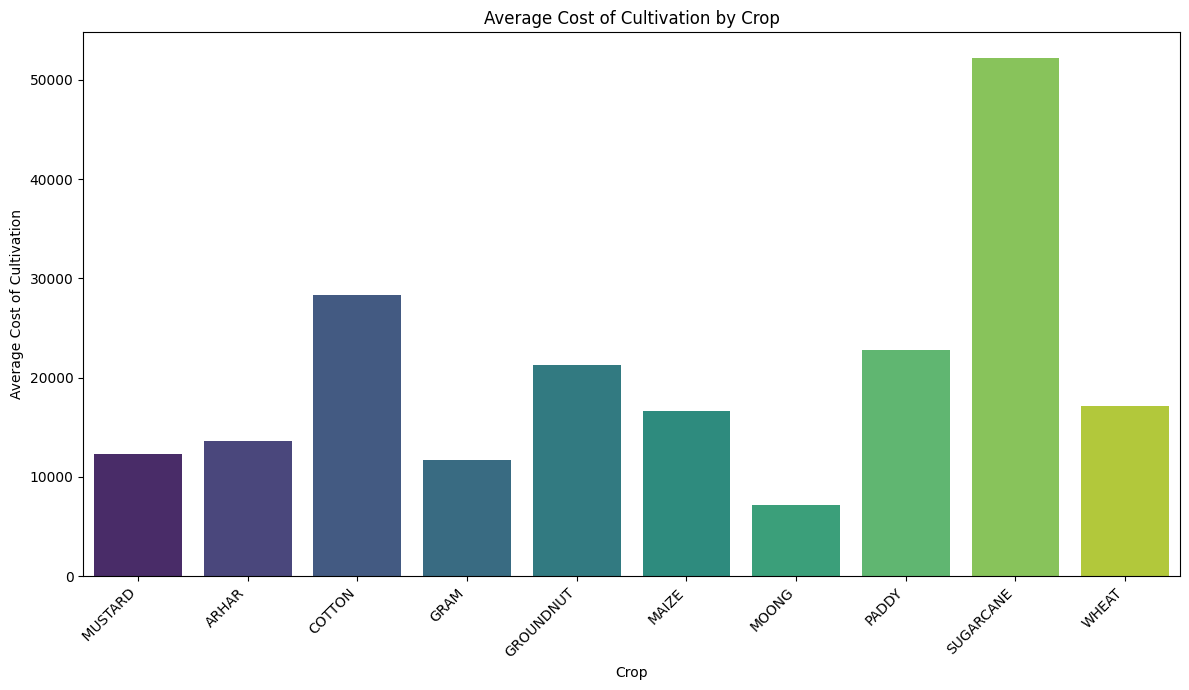

In [ ]:
# Bar plot: Average 'CostCultivation' per 'Crop'
if 'Crop' in df.columns and 'CostCultivation' in df.columns:
    plt.figure(figsize=(12, 7))
    avg_cost_by_crop = df.groupby('Crop')['CostCultivation'].mean().reset_index()
    sns.barplot(x='Crop', y='CostCultivation', data=avg_cost_by_crop, palette='viridis')
    plt.title('Average Cost of Cultivation by Crop')
    plt.xlabel('Crop')
    plt.ylabel('Average Cost of Cultivation')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("Cannot create bar plot: 'Crop' or 'CostCultivation' column not found.")

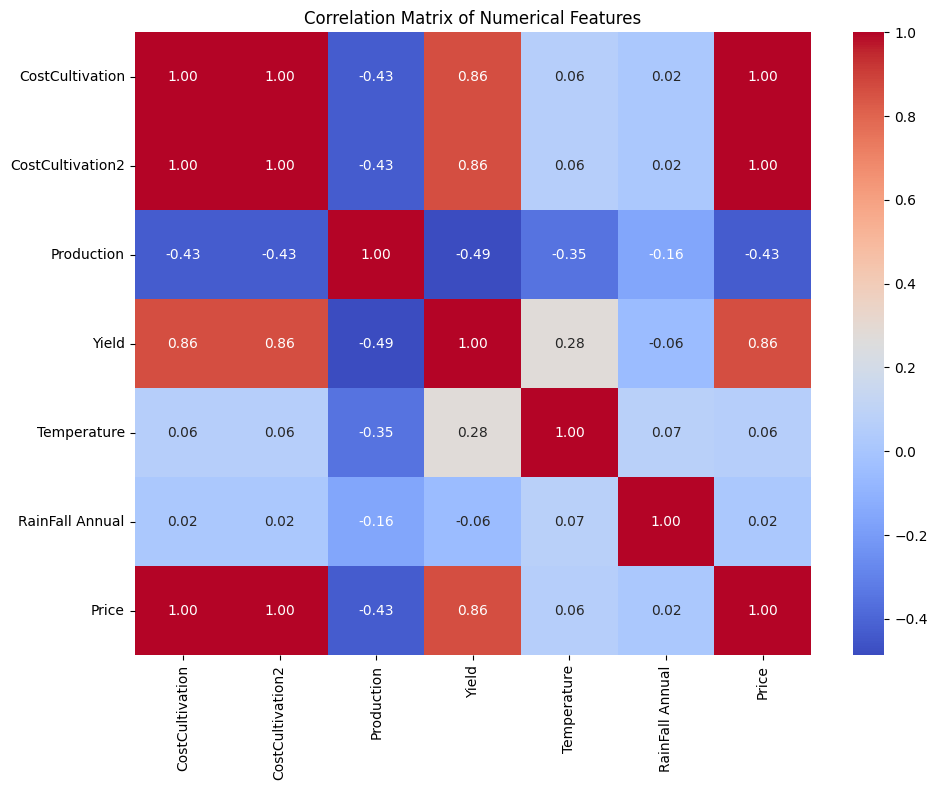

In [ ]:
# Correlation Heatmap for numerical columns
if len(numerical_cols) > 1:
    plt.figure(figsize=(10, 8))
    sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Matrix of Numerical Features')
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns to create a correlation heatmap.")

### Pie Chart: Proportion of Crops

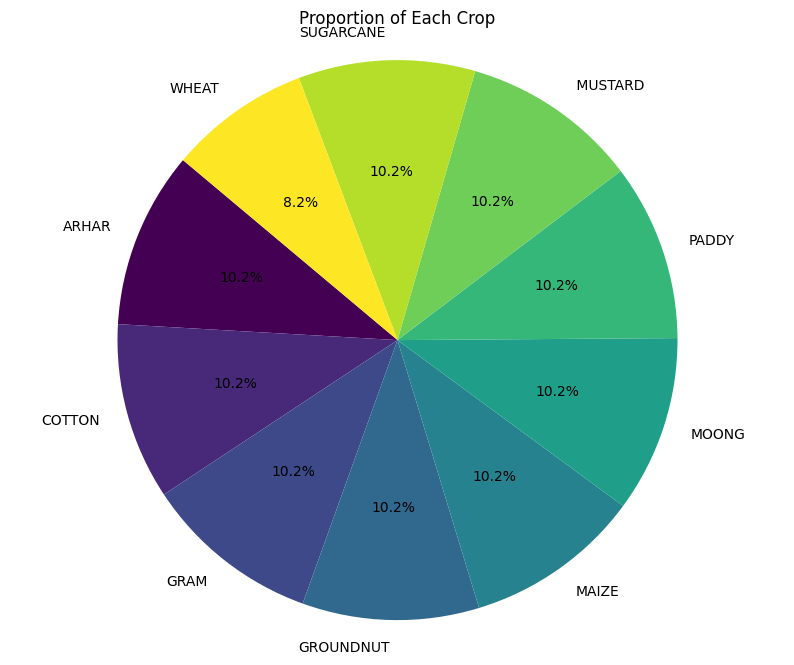

In [11]:
import numpy as np
# Pie Chart: Proportion of each 'Crop'
if 'Crop' in df.columns:
    crop_counts = df['Crop'].value_counts()
    plt.figure(figsize=(10, 8))
    # Generate colors from the 'viridis' colormap
    colors = plt.cm.viridis(np.linspace(0, 1, len(crop_counts)))
    plt.pie(crop_counts, labels=crop_counts.index, autopct='%1.1f%%', startangle=140, colors=colors)
    plt.title('Proportion of Each Crop')
    plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
    plt.show()
else:
    print("Cannot create pie chart: 'Crop' column not found.")